In [24]:
import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import xarray as xr
import rioxarray as rio
from matplotlib.patches import Patch

# Fire perimeter data exploration

In [4]:
# Load in eaton and palisades fire perimeter data
eaton_fp = os.path.join('data','eaton_perimeter_20250121.geojson')
eaton_fire = gpd.read_file(eaton_fp)

palisades_fp = os.path.join('data','palisades_perimeter_20250121.geojson')
palisades_fire = gpd.read_file(palisades_fp)

In [31]:
# Display eaton fire perimeter data
eaton_fire

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},1736294400000,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((398527.261 3781198.912, 398530..."


In [4]:
# Display palisades fire perimeter data
palisades_fire.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},1736208000000,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51975 34.02997, -118.5198..."


In [5]:
# Datatype of eaton fire perimeter
print(type(eaton_fire))

#Dataframe shape
print(eaton_fire.shape)

# Datatype of each column
print(eaton_fire.dtypes)

<class 'geopandas.geodataframe.GeoDataFrame'>
(1, 24)
OBJECTID            int64
YEAR_               int64
STATE              object
AGENCY             object
UNIT_ID            object
FIRE_NAME          object
type               object
INC_NUM            object
IRWINID            object
ALARM_DATE          int64
CONT_DATE           int64
CAUSE               int64
C_METHOD            int64
OBJECTIVE           int64
GIS_ACRES         float64
COMMENTS           object
COMPLEX_NAME       object
COMPLEX_ID         object
FIRE_NUM           object
GlobalID           object
DECADES            object
Shape__Area       float64
Shape__Length     float64
geometry         geometry
dtype: object


In [32]:
# Datatype of eaton fire perimeter
print(type(palisades_fire))

#Dataframe shape
print(palisades_fire.shape)

# Datatype of each column
print(palisades_fire.dtypes)

<class 'geopandas.geodataframe.GeoDataFrame'>
(1, 24)
OBJECTID            int64
YEAR_               int64
STATE              object
AGENCY             object
UNIT_ID            object
FIRE_NAME          object
type               object
INC_NUM            object
IRWINID            object
ALARM_DATE          int64
CONT_DATE           int64
CAUSE               int64
C_METHOD            int64
OBJECTIVE           int64
GIS_ACRES         float64
COMMENTS           object
COMPLEX_NAME       object
COMPLEX_ID         object
FIRE_NUM           object
GlobalID           object
DECADES            object
Shape__Area       float64
Shape__Length     float64
geometry         geometry
dtype: object


In [6]:
#Check CRS of eaton fire data
eaton_fire.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [7]:
#Check CRS of palisades fire data
palisades_fire.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [8]:
palisades_fire.shape

(1, 24)

In [9]:
print('Is eaton_fire geographic?: ', eaton_fire.crs.is_geographic)
print('Is eaton_fire projected?: ', eaton_fire.crs.is_projected)

Is eaton_fire geographic?:  True
Is eaton_fire projected?:  False


In [10]:
print('Is palisades_fire geographic?: ', palisades_fire.crs.is_geographic)
print('Is palisades_fire projected?: ', palisades_fire.crs.is_projected)

Is palisades_fire geographic?:  True
Is palisades_fire projected?:  False


The fire perimeters data uses the CRS: WGS 84 / Pseudo-Mercator and is geographic, not projected. Both fire perimeters have 1 row and 24 columns.

# NetCDF data import and exploration

In [7]:
#Load in LandSat data
cdf_fp = os.path.join('data','landsat8-2025-02-23-palisades-eaton.nc')
NetCDF = xr.open_dataset(cdf_fp)

sh: 1: getfattr: not found


In [8]:
#Look at LandSat data
NetCDF

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

In [13]:
#Look at LandSat data for the red band
NetCDF['red']

<xarray.DataArray 'red' (y: 1418, x: 2742)> Size: 16MB
[3888156 values with dtype=float32]
Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...
Attributes:
    grid_mapping:  spatial_ref

In [14]:
#Look at the green and blue band of LandSat Data
NetCDF[['green','blue']]

<xarray.Dataset> Size: 31MB
Dimensions:  (y: 1418, x: 2742)
Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...
Data variables:
    green    (y, x) float32 16MB ...
    blue     (y, x) float32 16MB ...

In [15]:
NetCDF.coords

Coordinates:
  * y        (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x        (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time     datetime64[ns] 8B ...

The variables contained within the landsat data are red, green, blue, nir08, swir22, and spatial_ref. The dimensions are (y: 1418, x: 2742) and the coordinates are in float64 and its units are in meters, the CRS is 
EPSG:32611

# Restoring geospatial information

In [9]:
#a.
NetCDF.rio.crs
#NetCDF is not a geospatial object

In [10]:
#b.
NetCDF.spatial_ref.crs_wkt
#NetCDF is in EPSG 32611

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [11]:
#c.
#Give the LandsatData the CRS of EPSG:32611 back
LandsatData = NetCDF.rio.write_crs("epsg:32611")

In [34]:
#Check LandsatDat has obtained the correct CRS
LandsatData.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]')

# True Color Image

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


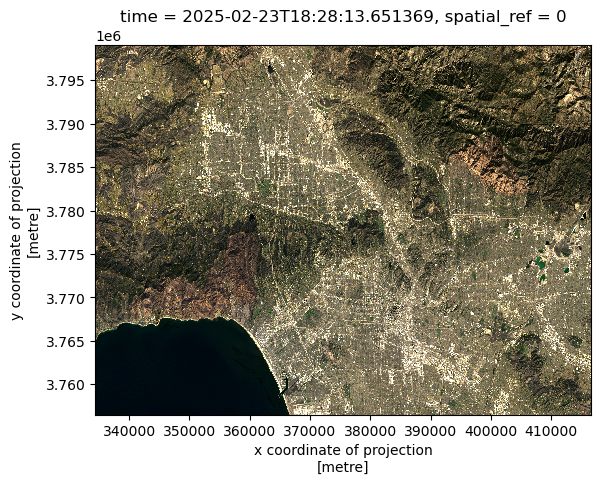

In [35]:
#a. #b.
#Select only red, green, and blue bands and plot the image
LandsatData[['red','green','blue']].to_dataarray().plot.imshow(robust=True)

array([ 145,  195,  248,  281,  294,  295,  296,  296,  297,  297,  298,
        298,  299,  299,  303,  304,  305,  305,  305,  306,  306,  306,
        307,  307,  308,  310,  310,  311,  312,  312,  321,  330,  352,
        353,  353,  375,  376,  376,  376,  377,  377,  378,  379,  449,
        450,  452,  463,  468,  468,  470,  471,  477,  478,  483,  484,
        511,  572,  587,  588,  592,  626,  629,  630,  644,  645,  662,
        684,  713,  741,  743,  743,  768,  836,  836,  836,  836,  837,
        853,  854,  952,  953,  954,  955,  960, 1009, 1010, 1028, 1068,
       1069, 1069, 1069, 1070, 1070, 1070, 1071, 1077, 1087, 1088, 1124,
       1190, 1191, 1230, 1253, 1255, 1278, 1282, 1283, 1307, 1310])

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


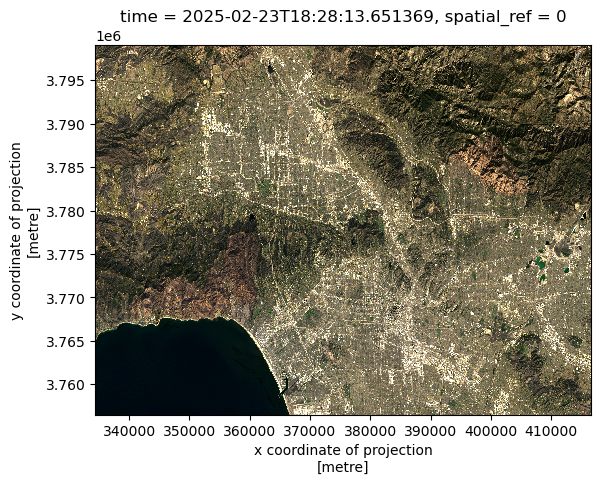

In [22]:
#c.
#Filter to blue band of landsat data
LandsatData['blue'].isnull().sum()

LandsatDataBlue = LandsatData['blue']

#Find the locations of the NA values in the blue band
locationsBlue = np.where(pd.isna(LandsatDataBlue))[0]
locationsBlue

In [23]:
#Filter to red band in landsat data
LandsatDataRed = LandsatData['red']

#Find the locations of the NA values in the red band
locationsRed = np.where(pd.isna(LandsatDataRed))[0]
locationsRed

array([], dtype=int64)

In [25]:
#Filter to green band in landsat data
LandsatDataGreen = LandsatData['green']

#Find the locations of the NA values in the green band
locationsGreen = np.where(pd.isna(LandsatDataGreen))[0]
locationsGreen

array([304])

In [26]:
#d.
#Blue band contains 109 NA's and the green band contains 1 NA

#Replace na's in blue and green bands
LandsatData['blue'] = LandsatData['blue'].fillna(0)
LandsatData['green'] = LandsatData['green'].fillna(0)

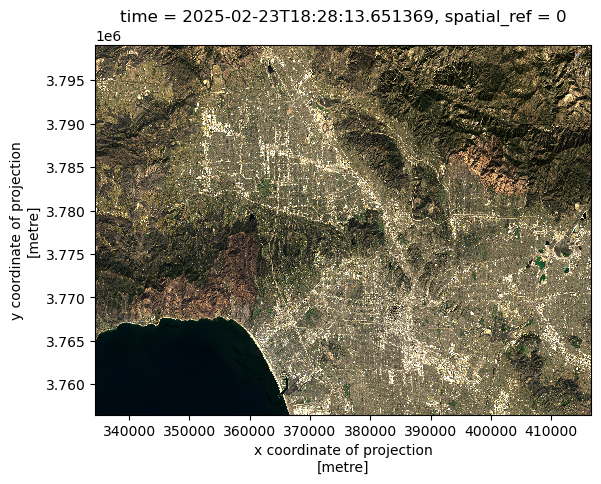

In [27]:
#e.
#Replot the data with NA's replaced with 0 to show no error message
LandsatData[['red','green','blue']].to_dataarray().plot.imshow(robust=True)

#f.
Part A wasn't able to show anything on the plot without the robust=True argument, but I would assume the first graph would have had less accurate color scaling, while the second graph doesn't show the error message after removing the NA values

# False Color Image

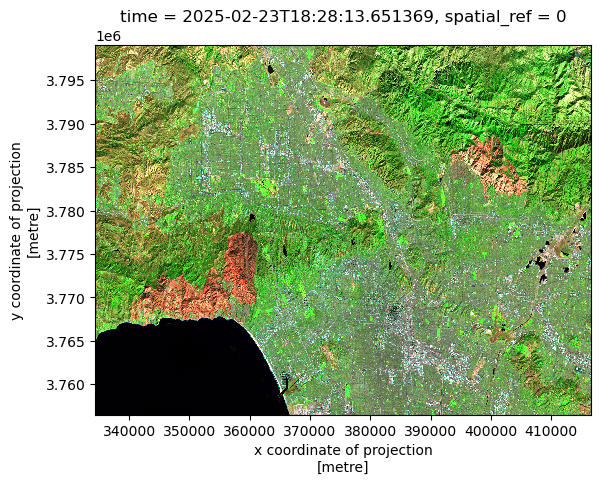

In [28]:
#Plot false color image with shortwave infrared, near infrared, and red bands plotted to the red, green and blue bands
LandsatData[['swir22','nir08','red']].to_dataarray().plot.imshow(robust=True)

# Map

In [16]:
# Project Eaton and Palisades to Landsat CRS
eaton_fire = eaton_fire.to_crs('epsg:32611')
palisades_fire = palisades_fire.to_crs('epsg:32611')

In [19]:
#Check all CRS's match
print(eaton_fire.crs == palisades_fire.crs)
print(eaton_fire.crs == LandsatData.rio.crs)

True
True


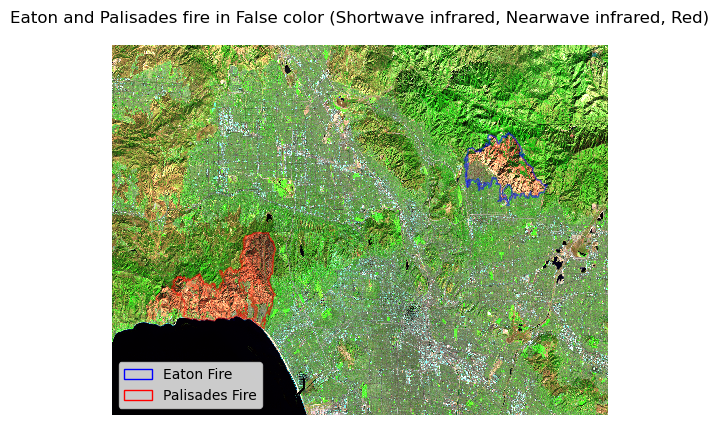

In [30]:
# Initialize empty figure
fig, ax = plt.subplots()

# Add data to axes
LandsatData[['swir22','nir08','red']].to_dataarray().plot.imshow(robust=True)

eaton_fire.plot(ax=ax,         # Add plot to axes
                 alpha=0.5,     # Adjust transparency
                 facecolor='none', edgecolor='blue'  # Update point color
                 )
palisades_fire.plot(ax=ax,         # Add plot to axes
                 alpha=0.5,     # Adjust transparency
                 facecolor='none', edgecolor='red'  # Update point color
                 )

LandsatData[['swir22','nir08','red']].to_dataarray().plot.imshow(robust=True)

# Update axes 
ax.set_title('Eaton and Palisades fire in False color (Shortwave infrared, Nearwave infrared, Red)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

#Add fire legend
plot_scale = [Patch(facecolor='none', edgecolor='blue',
                    label='Eaton Fire'),
             Patch(facecolor='none', edgecolor='red',
                   label='Palisades Fire')]
ax.legend(handles = plot_scale, loc = 'lower left')

ax.axis('off')

# Display figure
plt.show()

The map displays the ares of the Eaton and Palisades fires in Los Angeles in false color. Here the false color imagery is moving the shortwave infrared and nearwave infrared bands to the red and green channel and the red wavelengths to the blue band so that we may see these infrared spectrums with our own eyes. We can see how green this image is, indicating lots of nearwave infrared on the map.